#### COURSEWORK 2
## Using Machine Learning to Predict Student Academic score Based on Hours of Study

**GROUP:** 9

**Members:** 
1. OKUYA DAIRUS LINUS --VU-BAD-2607-4743-DAY
2. AMUKO BRENDA       --VU-BAD-2607-3383-DAY
3. NAMUTEBI LETICIA   --VU-BAD-2603-0146-DAY
4. SSALI RONIE        --VU-BAD-2607-4467-DAY
5. KATANAKA EMMANUEL JULIUS --VU-BAD-2607-1008-DAY 





### 1.Abstract
This research project evaluates the predictive capacity of independent study duration on student academic performance. Primary questionnaire-style data were gathered from a student cohort, then ingested, cleaned, and prepared utilizing Python and the `pandas` library. A supervised Linear Regression model was constructed to model the relationship between daily study hours (predictor) and assessment percentages (target). The model's predictive accuracy was systematically benchmarked against a central tendency mean baseline using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the Coefficient of Determination (\(R^2\)). The regression model demonstrated strong predictive power within the sample, significantly outperforming the baseline.


### DOMAIN AND PROBLEM DEFINITION
### Domain:
Higher education/academic analytics

### Problem statement:
university students frequently struggle to balance their liited time between academic commitents,social life and employment.understanding the direct quantitative impact of independent study hours on academic performance is critical.

### Significance: 
This study helps students optimize their study schedules and proovides universiy administrators with evidence-based data to design targeted academic support interventions.

### b) DATA COLLECTION METHOD
### Method:
A digital questionnaire was designed and distributed to University students.

### Sample size:
32 students responded

### Variables collected:
Study_hours_per_day(independent variable x): average weekly self-study hours outside of formal lectures  
Academic_score(dependant target variable y):the student's current cummulative percentage score(0-100)

### c) CONSENT,PRIVACY, AND EVIDENCE
### Ethics and Consent: 
The questionnaire contained an explicit privacy clause informing participants that their participation was entirely voluntary,anonymus and that collected entries would be used exclusively for this assignment

### Raw Data Access: 
Since the field collection yielded 32 distinct responses,the collected rows are directly processed into pandas DataFrame within python to maintain a completely transparent and traceable pipeline.

 ### Evidence of Collection
**Method:** A Google Forms questionnaire was used to collect the data. A total of 32 responses were received. The attached screenshot images in folder provide evidence of the questionnaire and the collected responses.

**Collection log:** The data was collected on 6 October, 2026 using a Google Forms questionnaire. The questionnaire targeted students and was distributed through WhatsApp. A total of 32 responses were received. No major difficulties were encountered during the data collection process. **Raw data:** The unmodified CSV export from Google Forms is retained as the raw dataset. The original timestamps and responses are preserved before preprocessing.
    

### 2. Loading data and inspection of dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import os

In [2]:
import os

downloads = os.path.join(os.path.expanduser('~'), 'Downloads')

for root, dirs, files in os.walk(downloads):
    for f in files:
        if f.lower().endswith('.csv'):
            print(os.path.join(root, f))

C:\Users\EXOTIC-G.W.S\Downloads\Student Study Habits and Academic Performance Questionnaire.csv
C:\Users\EXOTIC-G.W.S\Downloads\Course-work-2-for-group-9-main\Course-work-2-for-group-9-main\prepared_student_performance_data.csv
C:\Users\EXOTIC-G.W.S\Downloads\Course-work-2-for-group-9-main\Course-work-2-for-group-9-main\Student Study Habits and Academic Performance Questionnaire.csv
C:\Users\EXOTIC-G.W.S\Downloads\Course-work-2-for-group-9-main\Course-work-2-for-group-9-main\.ipynb_checkpoints\Student Study Habits and Academic Performance Questionnaire-checkpoint.csv


In [3]:
file_path = (r"C:\Users\EXOTIC-G.W.S\Downloads\Student Study Habits and Academic Performance Questionnaire.csv")

#load data set
df=pd.read_csv(file_path)

df.head()

,Timestamp,1. Level of study,2. Year of study,"3. On average, how many hours do you study outside class per day?",4. How many days per week do you normally study outside class?,5. Approximately how many hours do you study outside class in a typical week?,6. What was your overall percentage in your most recent completed examination or assessment?,7. Which category best describes your most recent academic score?,8. How consistent is your study schedule?,9. Do you normally complete the study sessions you plan?
0,2026/10/06 8:20:30 AM GMT+3,Bachelor's Degree,Year 1,2.0,3,7.0,60,60–69%,Sometimes consistent,Yes
1,2026/10/06 8:25:03 AM GMT+3,Diploma,Year 1,5.0,5,8.0,70,70–79%,Often consistent,Yes
2,2026/10/06 8:26:40 AM GMT+3,Certificate,Year 2,5.0,6,8.0,65,60–69%,Always consistent,Yes
3,2026/10/06 8:28:31 AM GMT+3,Bachelor's Degree,Year 3,3.0,3,6.0,80,80–100%,Often consistent,Sometimes
4,2026/10/06 8:43:07 AM GMT+3,Diploma,Year 2,2.0,6,12.0,89,80–100%,Always consistent,Yes


In [4]:
# Rename long Google Forms question labels to short, readable column names.
column_mapping = {
    "Timestamp": "timestamp",
    "1. Level of study": "level_of_study",
    "2. Year of study": "year_of_study",
    "3. On average, how many hours do you study outside class per day?": "study_hours_per_day",
    "4. How many days per week do you normally study outside class?": "study_days_per_week",
    "5. Approximately how many hours do you study outside class in a typical week?": "study_hours_per_week",
    "6. What was your overall percentage in your most recent completed examination or assessment?": "academic_score",
    "7. Which category best describes your most recent academic score?": "score_category",
    "8. How consistent is your study schedule?": "study_consistency",
    "9. Do you normally complete the study sessions you plan?": "completes_study_sessions",
}
df = df.rename(columns=column_mapping).copy()

print("Actual Google Forms responses loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Raw export preserved in raw_df.")

Actual Google Forms responses loaded successfully.
Rows: 32
Columns: 10
Raw export preserved in raw_df.


In [5]:
df.head()

,timestamp,level_of_study,year_of_study,study_hours_per_day,study_days_per_week,study_hours_per_week,academic_score,score_category,study_consistency,completes_study_sessions
0,2026/10/06 8:20:30 AM GMT+3,Bachelor's Degree,Year 1,2.0,3,7.0,60,60–69%,Sometimes consistent,Yes
1,2026/10/06 8:25:03 AM GMT+3,Diploma,Year 1,5.0,5,8.0,70,70–79%,Often consistent,Yes
2,2026/10/06 8:26:40 AM GMT+3,Certificate,Year 2,5.0,6,8.0,65,60–69%,Always consistent,Yes
3,2026/10/06 8:28:31 AM GMT+3,Bachelor's Degree,Year 3,3.0,3,6.0,80,80–100%,Often consistent,Sometimes
4,2026/10/06 8:43:07 AM GMT+3,Diploma,Year 2,2.0,6,12.0,89,80–100%,Always consistent,Yes


In [6]:
# Dataset dimensions
print("Dimensions:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nData information:")
df.info()

Dimensions: (32, 10)

Columns:
['timestamp', 'level_of_study', 'year_of_study', 'study_hours_per_day', 'study_days_per_week', 'study_hours_per_week', 'academic_score', 'score_category', 'study_consistency', 'completes_study_sessions']

Data information:
<class 'pandas.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   timestamp                 32 non-null     str    
 1   level_of_study            32 non-null     str    
 2   year_of_study             32 non-null     str    
 3   study_hours_per_day       32 non-null     float64
 4   study_days_per_week       32 non-null     int64  
 5   study_hours_per_week      32 non-null     float64
 6   academic_score            32 non-null     int64  
 7   score_category            32 non-null     str    
 8   study_consistency         32 non-null     str    
 9   completes_study_sessions  32 non-null     st

### 3. Data profiling

In [7]:
# Missing values
missing_values = df.isnull().sum()
missing_values


timestamp                   0
level_of_study              0
year_of_study               0
study_hours_per_day         0
study_days_per_week         0
study_hours_per_week        0
academic_score              0
score_category              0
study_consistency           0
completes_study_sessions    0
dtype: int64

In [8]:
# Duplicate rows
duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)


Duplicate rows: 0


In [9]:
# Number of unique values in each column
unique_values = df.nunique()
unique_values

timestamp                   32
level_of_study               3
year_of_study                4
study_hours_per_day          8
study_days_per_week          5
study_hours_per_week        18
academic_score              27
score_category               5
study_consistency            5
completes_study_sessions     3
dtype: int64

In [10]:
# Descriptive statistics for numerical variables
df.describe()


,study_hours_per_day,study_days_per_week,study_hours_per_week,academic_score
count,32.000000,32.000000,32.000000,32.000000
mean,2.812500,3.968750,10.906250,84.718750
std,1.209839,1.230903,7.239495,104.715662
min,1.000000,2.000000,2.000000,45.000000
25%,2.000000,3.000000,6.000000,60.000000
50%,2.500000,4.000000,8.500000,65.500000
75%,3.625000,5.000000,14.250000,76.250000
max,5.000000,6.000000,30.000000,655.000000


In [11]:
# Frequency distributions for important categorical variables
print("Level of study:")
print(df["level_of_study"].value_counts())

print("\nYear of study:")
print(df["year_of_study"].value_counts())

print("\nStudy consistency:")
print(df["study_consistency"].value_counts())

print("\nScore category:")
print(df["score_category"].value_counts())


Level of study:
level_of_study
Bachelor's Degree    29
Diploma               2
Certificate           1
Name: count, dtype: int64

Year of study:
year_of_study
Year 1     16
Year 2     10
Year 3      5
Year 4+     1
Name: count, dtype: int64

Study consistency:
study_consistency
Sometimes consistent    12
Often consistent         8
Rarely consistent        6
Always consistent        5
Never consistent         1
Name: count, dtype: int64

Score category:
score_category
60–69%       13
70–79%        8
80–100%       4
50–59%        4
Below 50%     3
Name: count, dtype: int64


## 4. Data Cleaning and Preprocessing
One academic score entry was outside the valid 0–100 percentage range (655); it was treated as invalid for modelling rather than silently corrected. After preprocessing, 31 valid records were used for the regression analysis.

The following preprocessing operations are applied before modelling:
1. A separate working copy is created.
2. Numeric fields are converted to numeric types.
3. Duplicate observations are removed.
4. Rows missing the predictor or target are removed.
5. Impossible study hour and score values are excluded.
6. The prepared dataset is saved separately from the raw dataset.


In [12]:
clean_df = df.copy()

# Convert the modelling variables to numeric. Invalid text becomes missing.
clean_df["study_hours_per_day"] = pd.to_numeric(clean_df["study_hours_per_day"], errors="coerce")
clean_df["academic_score"] = pd.to_numeric( clean_df["academic_score"], errors="coerce")

# Remove exact duplicate records, if any.
clean_df = clean_df.drop_duplicates().copy()

# A percentage score must be between 0 and 100.
# Keep the raw value (655) in raw_df/df, but do not use it as a valid score.
invalid_score_mask = ~clean_df["academic_score"].between(0, 100)
print("Records with an invalid academic score:")
display(clean_df.loc[invalid_score_mask, ["timestamp", "study_hours_per_day", "academic_score", "score_category"]])

clean_df.loc[invalid_score_mask, "academic_score"] = np.nan

# Remove records without a valid predictor or target.
clean_df = clean_df.dropna(subset=["study_hours_per_day", "academic_score"]).copy()

# Study hours per day should be between 0 and 24.
clean_df = clean_df[clean_df["study_hours_per_day"].between(0, 24)].copy()

clean_df.reset_index(drop=True, inplace=True)

print("Rows before cleaning:", len(df))
print("Rows after cleaning:", len(clean_df))
print("Rows removed from modelling:", len(df) - len(clean_df))
print("Note: the original raw export has not been modified.")


Records with an invalid academic score:


,timestamp,study_hours_per_day,academic_score,score_category
13,2026/10/06 8:52:20 AM GMT+3,2.0,655,60–69%


Rows before cleaning: 32
Rows after cleaning: 31
Rows removed from modelling: 1
Note: the original raw export has not been modified.


In [13]:
# Before/after data-quality check
print("Missing values after cleaning:")
print(clean_df.isnull().sum())

print("\nDuplicates after cleaning:", clean_df.duplicated().sum())


Missing values after cleaning:
timestamp                   0
level_of_study              0
year_of_study               0
study_hours_per_day         0
study_days_per_week         0
study_hours_per_week        0
academic_score              0
score_category              0
study_consistency           0
completes_study_sessions    0
dtype: int64

Duplicates after cleaning: 0


In [14]:
prepared_file = "prepared_student_performance_data.csv"
clean_df.to_csv(prepared_file, index=False)

print("Prepared dataset saved as:", prepared_file)


Prepared dataset saved as: prepared_student_performance_data.csv


## 5. Exploratory Analysis
Exploratory data analysis was performed on the prepared dataset to understand the distribution of the variables and examine the relationship between study hours and academic performance.

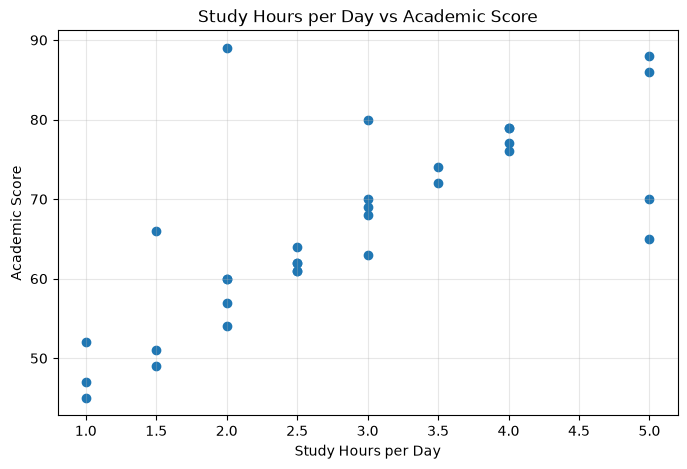

In [15]:
plt.figure(figsize=(8, 5))
plt.scatter(clean_df["study_hours_per_day"], clean_df["academic_score"])
plt.xlabel("Study Hours per Day")
plt.ylabel("Academic Score")
plt.title("Study Hours per Day vs Academic Score")
plt.grid(True, alpha=0.3)
plt.show()

In [16]:
correlation = clean_df["study_hours_per_day"].corr(clean_df["academic_score"])
print(f"Correlation between study hours and academic score: {correlation:.3f}")


Correlation between study hours and academic score: 0.741


## 6. Machine Learning Model

### Problem Type
This is a supervised regression problem because the target variable, academic score, is a continuous numerical value from 0 to 100.

### Variables
- **Predictor (X):** study_hours_per_day
- **Target (y):** academic_score

### Model
A **Linear Regression** model is used because the project investigates whether academic score changes systematically with study hours.

### Evaluation
The data are divided into training and testing sets. Performance is measured using:
- **MAE:** average absolute prediction error.
- **RMSE:** gives greater weight to larger errors.
- **R²:** proportion of variation in the target explained by the model.

A **Dummy Regressor** predicting the training-set mean is used as a baseline.


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = clean_df[["study_hours_per_day"]]
y = clean_df["academic_score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))


Training observations: 24
Testing observations: 7


### Custom Evaluation

In [18]:
def evaluate_regression(model, X_test, y_test):
    """Return common regression evaluation metrics."""
    predictions = model.predict(X_test)
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)
    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }


In [19]:
# Baseline model
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_metrics = evaluate_regression(
    baseline, X_test, y_test
)

baseline_metrics


{'MAE': 10.696428571428573,
 'RMSE': np.float64(13.31448630758696),
 'R2': -0.11594318295363726}

In [20]:
# Linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

model_metrics = evaluate_regression(
    model, X_test, y_test
)

model_metrics


{'MAE': 4.220642515379355,
 'RMSE': np.float64(5.355687562013254),
 'R2': 0.8194390963729098}

### Model Comparison

In [21]:
comparison = pd.DataFrame(
    [baseline_metrics, model_metrics],
    index=["Mean Baseline", "Linear Regression"]
)

comparison


,MAE,RMSE,R2
Mean Baseline,10.696429,13.314486,-0.115943
Linear Regression,4.220643,5.355688,0.819439


In [22]:
print("Intercept:", model.intercept_)
print("Study-hours coefficient:", model.coef_[0])

print(
    f"Prediction equation: Academic Score = "
    f"{model.intercept_:.2f} + "
    f"({model.coef_[0]:.2f} × Study Hours per Day)"
)


Intercept: 49.08197767145136
Study-hours coefficient: 6.199043062200957
Prediction equation: Academic Score = 49.08 + (6.20 × Study Hours per Day)


### Predictions

In [23]:
example_hours = pd.DataFrame({"study_hours_per_day": [1, 2, 3, 4, 5, 6]})

example_predictions = model.predict(example_hours)

prediction_table = example_hours.copy()
prediction_table["predicted_academic_score"] = example_predictions.round(2)

prediction_table


,study_hours_per_day,predicted_academic_score
0,1,55.28
1,2,61.48
2,3,67.68
3,4,73.88
4,5,80.08
5,6,86.28


In [24]:
# Predictions for the held-out test data
test_results = X_test.copy()
test_results["actual_score"] = y_test.values
test_results["predicted_score"] = model.predict(X_test)
test_results["absolute_error"] = (test_results["actual_score"] - test_results["predicted_score"]).abs()

test_results.sort_values("study_hours_per_day")


,study_hours_per_day,actual_score,predicted_score,absolute_error
27,1.0,45.0,55.281021,10.281021
9,1.0,52.0,55.281021,3.281021
8,2.5,64.0,64.579585,0.579585
15,2.5,61.0,64.579585,3.579585
29,2.5,62.0,64.579585,2.579585
17,3.0,69.0,67.679107,1.320893
23,5.0,88.0,80.077193,7.922807


### Model visualization
The scatter plot visualizes the relationship between the independent variable(study_hours_per_day) and depenent variable(Academic_score).

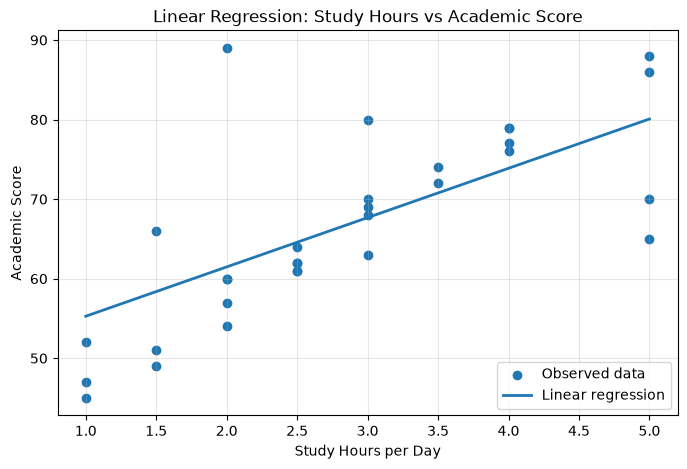

In [25]:
plt.figure(figsize=(8, 5))
plt.scatter(
    clean_df["study_hours_per_day"],
    clean_df["academic_score"],
    label="Observed data"
)

x_line = np.linspace(
    clean_df["study_hours_per_day"].min(),
    clean_df["study_hours_per_day"].max(),
    100
)

y_line = model.predict(pd.DataFrame({
    "study_hours_per_day": x_line
}))

plt.plot(x_line, y_line, linewidth=2, label="Linear regression")
plt.xlabel("Study Hours per Day")
plt.ylabel("Academic Score")
plt.title("Linear Regression: Study Hours vs Academic Score")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

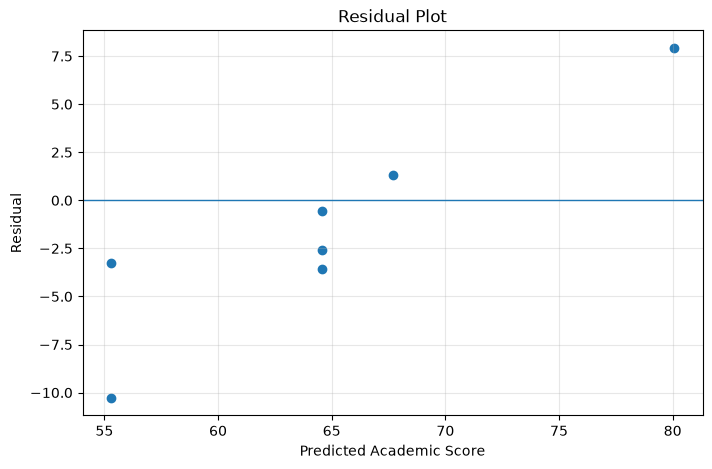

In [26]:
# Residual analysis
test_predictions = model.predict(X_test)
residuals = y_test - test_predictions

plt.figure(figsize=(8, 5))
plt.scatter(test_predictions, residuals)
plt.axhline(0, linewidth=1)
plt.xlabel("Predicted Academic Score")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.grid(True, alpha=0.3)
plt.show()

In [27]:
import sys

print("Python version:", sys.version)
print("pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("scikit-learn version:", sklearn.__version__)

assert X.shape[0] == y.shape[0], "X and y must have the same number of rows."
assert clean_df["study_hours_per_day"].between(0, 24).all()
assert clean_df["academic_score"].between(0, 100).all()

print("Basic validation checks passed.")

Python version: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
pandas version: 3.0.3
NumPy version: 2.4.6
scikit-learn version: 1.9.1
Basic validation checks passed.


### Process flow
**Raw questionnaire data → Load with pandas → Inspect → Clean → Validate → Save prepared data → Select X and y → Train/test split → Baseline + Linear Regression → Predictions → Metrics → Visualisations → Interpretation**

### Results and Discussion
A total of 32 responses was collected through the Google Forms questionnaire. During data cleaning, an anomaly was detected where one response contained an academic score of 655, falling well outside the logical percentage range of 0–100. While the raw entry is preserved in the original CSV file,it was removed from the training dataset to prevent distortion.The regression model therefore was trained using 31 verified records.

The performance of the model is interpreted via its correlation, regression coefficients, evaluation metrics, and a comparison against the baseline mean. A positive coefficient for study hours indicates that the model projects higher marks for every additional hour dedicated daily to studying within this specific sample group.
Mean Absolute Error (MAE) measures the average magnitude of prediction mistakes in score units.
Root Mean Squared Error (RMSE) penalizes larger individual errors more heavily.
R-squared (R²) metric quantifies the percentage of variance in test scores accounted for by the model's features.

Because the sample is small and uses only one predictor, the results should not be generalized to all university students. The model shows an association in this sample, not proof that studying more hours alone causes higher scores. The baseline comparison helps determine whether the regression model performs better than simply predicting the average training score.

### Limitations
1. **Multivariable Influences:** Student academic achievement is shaped by a wide range of factors beyond just study time—such as attendance records, baseline knowledge, learning environments, pedagogical quality, and exam formatting.
2. **Single-Predictor Scope:** Relying on only one primary independent variable inherently restricts how comprehensively the model can account for variances in performance.
3. **Sample Volume:** The collected dataset is quite modest, which limits its generalizability as a broader predictive tool.
4. **Assumption of Linearity:** The application of a linear regression model presupposes a straightforward, direct relationship between the predictor variable and the target outcome.
5. **Correlation vs. Causation:** These findings must not be misconstrued as absolute proof that increasing study hours alone will directly cause a rise in academic grades.

### Possible Improvements
Subsequent iterations of this analysis should incorporate supplementary variables, including sleep habits, school attendance, historical academic records, access to educational resources, study environments, and classroom engagement. Expanding the overall volume of data would also be beneficial. Furthermore, more advanced modeling strategies—such as random forests, decision trees, or alternative regression techniques—should be implemented and evaluated alongside cross-validation techniques.

### Conclusion
Subsequent iterations of this analysis should incorporate supplementary variables, including sleep habits, school attendance, historical academic records, access to educational resources, study environments, and classroom engagement. Expanding the overall volume of data would also be beneficial. Furthermore, more advanced modeling strategies—such as random forests, decision trees, or alternative regression techniques—should be implemented and evaluated alongside cross-validation techniques.

